In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import MDAnalysis as mda
import MDAnalysis
from typing import Dict, Tuple
import os
import seaborn as sns

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))

    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    try:
        chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    except:
        chi2, phi, thetas = rewdata[0], rewdata[1], rewdata[2] # in case just one theta ran
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

def get_coords(topo_pdb, traj_xtc, select='name CA', start=None, stop=None, step=None):

    u = mda.Universe(topo_pdb, traj_xtc)
    ca = u.select_atoms(select)

    # collect coordinates of CA atoms across frames
    coords = []
    for ts in u.trajectory[start:stop:step]:
        coords.append(ca.positions.copy())
    coords = np.array(coords)  # shape = (n_frames, n_atoms, 3)
    n_frames, n_atoms, _ = coords.shape

    return coords


def compute_weighted_rmsf(topo_pdb, coords, weights=None, select='name CA'):
    """
    Compute unweighted and ensemble-weighted RMSF per residue using C-alpha atoms.
    
    Parameters
    ----------
    traj_xtc : str
        Path to the aligned trajectory (.xtc).
    topo_pdb : str
        Path to the topology (.pdb).
    weights : array-like or None
        Frame weights (length = number of frames considered).
        If None, unweighted RMSF is computed.
    select : str
        Atom selection string (default: 'name CA').
    start, stop, step : int, optional
        Frame slicing parameters.

    Returns
    -------
    results : dict
        {
            'resids': residue IDs,
            'resnames': residue names,
            'rmsf_unweighted': np.ndarray,
            'rmsf_weighted': np.ndarray (None if weights not provided)
        }
    """
    u = mda.Universe(topo_pdb)
    ca = u.select_atoms(select)

    n_frames = coords.shape[0]

    if weights is not None:
        weights = np.asarray(weights, dtype=float)
        if weights.size != n_frames:
            raise ValueError(f"weights length ({weights.size}) != number of frames ({n_frames})")

        weights /= np.sum(weights)  # normalize
    else:
        weights = np.ones(n_frames) / n_frames

    # Weighted average position for each atom
    mean_pos = np.average(coords, axis=0, weights=weights)

    # Weighted RMSF per atom
    diff = coords - mean_pos
    sq_diff = np.sum(diff**2, axis=2)  # shape = (n_frames, n_atoms)
    rmsf_weighted_per_atom = np.sqrt(np.average(sq_diff, axis=0, weights=weights))

    # Unweighted RMSF (for comparison)
    mean_pos_unweighted = np.mean(coords, axis=0)
    rmsf_unweighted_per_atom = np.sqrt(np.mean(np.sum((coords - mean_pos_unweighted)**2, axis=2), axis=0))

    # Map to residues
    resids = np.array([atom.resid for atom in ca])
    resnames = np.array([atom.resname for atom in ca])

    unique_res = np.unique(resids)
    rmsf_unweighted = []
    rmsf_weighted = []
    resnames_out = []

    for resid in unique_res:
        mask = resids == resid
        resname = resnames[mask][0]
        rmsf_unweighted.append(np.mean(rmsf_unweighted_per_atom[mask]))
        rmsf_weighted.append(np.mean(rmsf_weighted_per_atom[mask]))
        resnames_out.append(resname)

    return unique_res, resnames_out, np.array(rmsf_unweighted)/10, np.array(rmsf_weighted)/10 # convert to nm

outpath = './RMSF_analyses/'

In [6]:
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']
proteins = ['ACBP','ACP','alpha3D','At2g44940','Barnase','BarstarK60','betalactamasePSE4','BPTI','Calbindin','CalcineurinB','CI2','ci2_I29A_I37H','DAXX','FKBP12',
            'Galectin1','GB3','H14','hFGF1','Hisactophilin1','HIVintegrase','HP36', 'Im7','Jarastatin','Lactalbumin','lDHFR','Lysozyme','NHP2L1','PeroxiredoxinQ','RNaseA',
            'RNaseH','RNaseT1','SAMP1','Staph_nuclease_P117G_H124L','T4_lysozyme','Ubiquitin']

for protein in proteins:
    print(f'Analysing {protein}...')
    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=1
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4.5, 3.5 * n_models))


    # precalculate coordinates
    for i in range(len(traj_names)):
        u = mda.Universe(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
        if i==0:
            coords = get_coords(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
        else:
            tmpcoords = get_coords(f'../../MD_DATA/{protein}/protein.pdb', f'../../MD_DATA/{protein}/{traj_names[i]}')
            # append
            coords = np.concatenate((coords, tmpcoords), axis=0)   


    for i, model in enumerate(models):
        if not os.path.exists(f"../../MD_DATA/{protein}/{model}/wopt.npy") and not os.path.exists(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy"):
            print(f'No reweighting results for {protein}/{model}, skipping ...')
            continue
        
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        if model in ('rewBV2006', 'rewBV2006ang'):
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
        else:
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

        # posterior RMSF
        model_res, _, rmsf_prior, rmsf_post = compute_weighted_rmsf(f'../../MD_DATA/{protein}/protein.pdb', coords, weights=wopt)

        # --- Plot 4: RMSF data ---

        ax = axes[i]

        # prior and posterior RMSE

        # experimental and ensemble averaged values
        ratio = np.round(np.mean(np.array(rmsf_post)/np.array(rmsf_prior)),2)
        final_neff = np.round(stats['final neff'][0], 2)
        ax.set_title(f"{model}, ratio = {ratio}"+", N$_{eff}$"+f" = {final_neff}")
        ax.plot(model_res, rmsf_prior, color="tab:blue", label="Prior", zorder=20)
        ax.plot(model_res, rmsf_post, color="tab:red", label="Posterior", zorder=20)

        ax.set_ylabel('RMSF (nm)')
        ax.set_xlabel('Residue')

        ax.set_ylim(0,1)

        # set legend
        ax.legend(loc='upper center')

        # save data
        savedf = pd.DataFrame()
        savedf['Residue'] = model_res
        savedf['Prior'] = np.round(rmsf_prior,3)
        savedf['Posterior'] = np.round(rmsf_post,3)
        savedf.to_csv(outpath+f"{protein}_{model}_RMSF.csv")

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(outpath+f"{protein}_HDXrew_RMSF.png", dpi=200, bbox_inches="tight")
    plt.close()


Analysing ACBP...


/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

Analysing ACP...


/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

Analysing alpha3D...


...

/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

Analysing T4_lysozyme...


/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

Analysing Ubiquitin...


/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following atom types: 
  warnings.warn("Failed to guess the mass for the following atom types: {}".format(atom_type))
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/PDBParser.py:345: UserWarning: Unknown element  found for some atoms. These have been given an empty element record. If needed they can be guessed using MDAnalysis.topology.guessers.
  warnings.warn(wmsg)
/home/thd711/.conda/envs/HDXproject/lib/python3.8/site-packages/MDAnalysis/topology/guessers.py:146: UserWarning: Failed to guess the mass for the following 

In [8]:
model

'rewM10DH_scaled'

In [3]:
model

'rewM10DH'

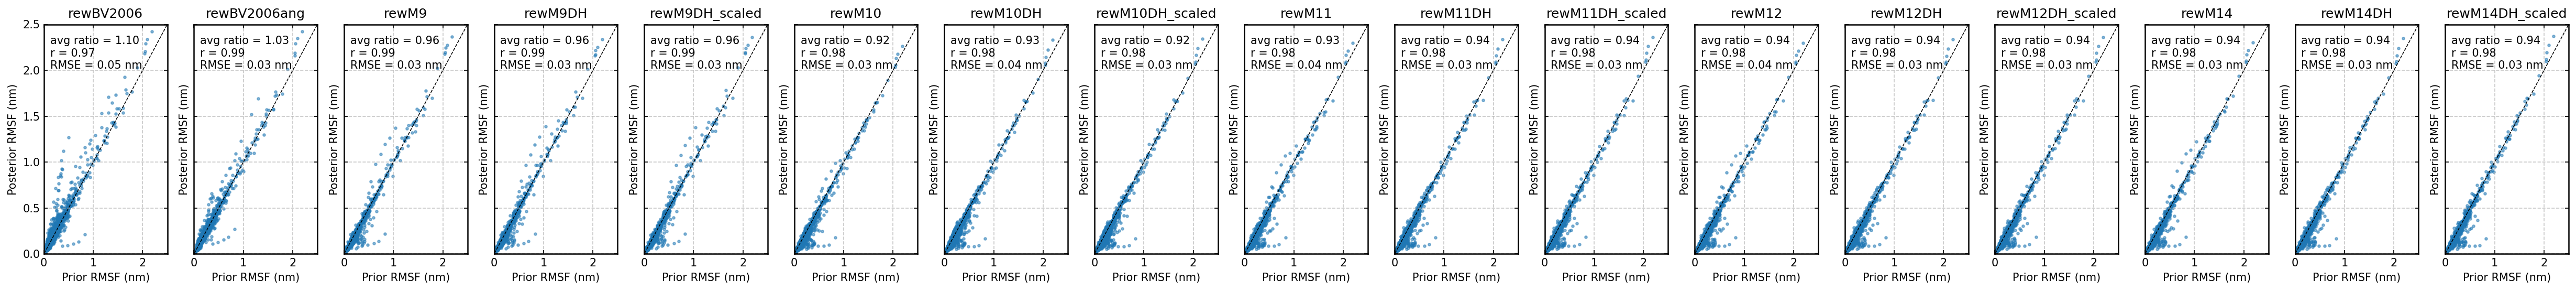

In [7]:
# scatter plots of all models with datapoints from all proteins: prior RMSF vs posterior RMSF & average ratio

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

proteins = ['ACBP','ACP','alpha3D','At2g44940','Barnase','BarstarK60','betalactamasePSE4','BPTI','Calbindin','CalcineurinB','CI2','ci2_I29A_I37H','DAXX','FKBP12',
            'Galectin1','GB3','H14','hFGF1','Hisactophilin1','HIVintegrase','HP36', 'Im7','Jarastatin','Lactalbumin','lDHFR','Lysozyme','NHP2L1','PeroxiredoxinQ','RNaseA',
            'RNaseH','RNaseT1','SAMP1','Staph_nuclease_P117G_H124L','T4_lysozyme','Ubiquitin']

fig, axes = plt.subplots(1, len(models), figsize=(35, 4), sharex=True, sharey=True)

for ax, model in zip(axes, models):

    prior = np.array([])
    posterior = np.array([])

    # collect data across all proteins
    for protein in proteins:
        if not os.path.exists(outpath + f"{protein}_{model}_RMSF.csv"):
            print(f'No data for {protein}/{model}, skipping ...')
            continue
        dat = pd.read_csv(outpath + f"{protein}_{model}_RMSF.csv")
        prior = np.concatenate((prior, np.array(dat['Prior'])))
        posterior = np.concatenate((posterior, np.array(dat['Posterior'])))

    # compute metrics
    ratio = posterior / prior
    mean_ratio = np.nanmean(ratio)
    r, _ = scipy.stats.pearsonr(prior, posterior)
    rmse = RMSE(prior, posterior)

    # scatter plot
    ax.scatter(prior, posterior, s=5, alpha=0.5)
    ax.set_title(model)
    ax.set_xlabel('Prior RMSF (nm)')
    ax.set_ylabel('Posterior RMSF (nm)')

    # add stats to subplot
    ax.text(
        0.05, 0.95,
        f"avg ratio = {mean_ratio:.2f}\nr = {r:.2f}\nRMSE = {rmse:.2f} nm",
        transform=ax.transAxes,
        va='top'
    )

    ax.set_ylim(0,2.5)
    ax.set_xlim(0,2.5)

    # diagnole
    ax.plot([-1, 5], [-1, 5], color = 'black', linewidth = 0.75, linestyle = 'dashed')

# shared labels
#fig.text(0.5, 0.04, "Prior RMSF (nm)", ha='center')
#fig.text(0.06, 0.5, "Posterior RMSF (nm)", va='center', rotation='vertical')

plt.tight_layout(rect=[0.06, 0.05, 1, 1])
plt.savefig(outpath+'FoldedProteins_RMSF_HDXrew.png',dpi=200)

    


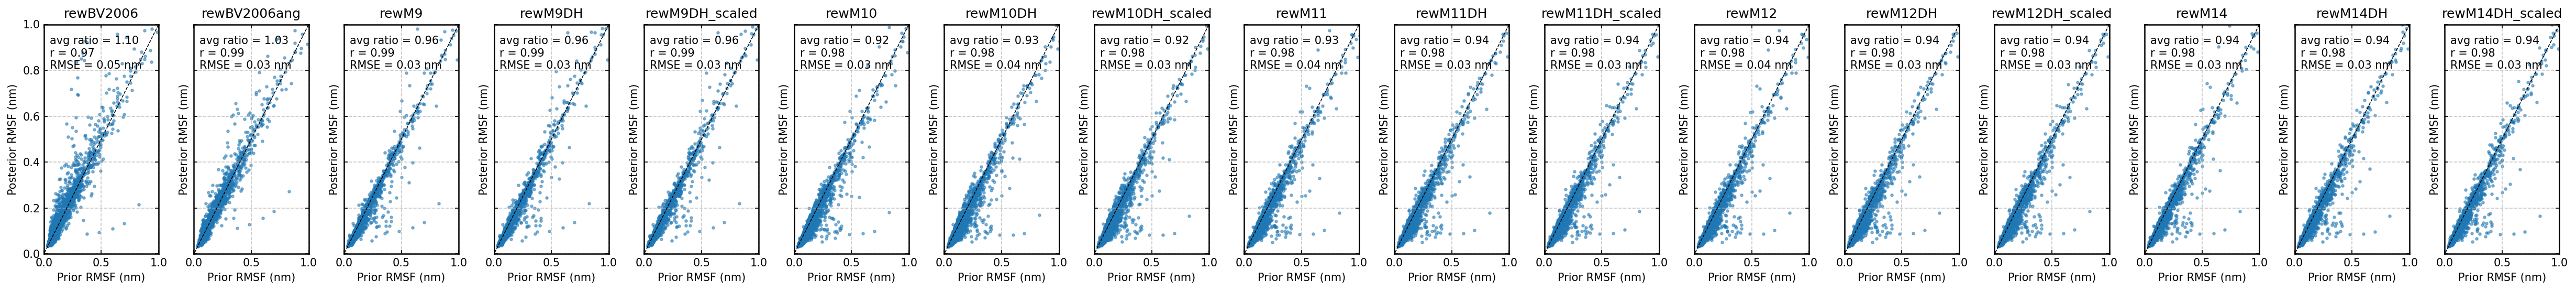

In [8]:
# scatter plots of all models with datapoints from all proteins: prior RMSF vs posterior RMSF & average ratio

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']
proteins = ['ACBP','ACP','alpha3D','At2g44940','Barnase','BarstarK60','betalactamasePSE4','BPTI','Calbindin','CalcineurinB','CI2','ci2_I29A_I37H','DAXX','FKBP12',
            'Galectin1','GB3','H14','hFGF1','Hisactophilin1','HIVintegrase','HP36', 'Im7','Jarastatin','Lactalbumin','lDHFR','Lysozyme','NHP2L1','PeroxiredoxinQ','RNaseA',
            'RNaseH','RNaseT1','SAMP1','Staph_nuclease_P117G_H124L','T4_lysozyme','Ubiquitin']

fig, axes = plt.subplots(1, len(models), figsize=(35, 4), sharex=True, sharey=True)

for ax, model in zip(axes, models):

    prior = np.array([])
    posterior = np.array([])

    # collect data across all proteins
    for protein in proteins:
        if not os.path.exists(outpath + f"{protein}_{model}_RMSF.csv"):
            print(f'No data for {protein}/{model}, skipping ...')
            continue
        dat = pd.read_csv(outpath + f"{protein}_{model}_RMSF.csv")
        prior = np.concatenate((prior, np.array(dat['Prior'])))
        posterior = np.concatenate((posterior, np.array(dat['Posterior'])))

    # compute metrics
    ratio = posterior / prior
    mean_ratio = np.nanmean(ratio)
    r, _ = scipy.stats.pearsonr(prior, posterior)
    rmse = RMSE(prior, posterior)

    # scatter plot
    ax.scatter(prior, posterior, s=5, alpha=0.5)
    ax.set_title(model)
    ax.set_xlabel('Prior RMSF (nm)')
    ax.set_ylabel('Posterior RMSF (nm)')

    # add stats to subplot
    ax.text(
        0.05, 0.95,
        f"avg ratio = {mean_ratio:.2f}\nr = {r:.2f}\nRMSE = {rmse:.2f} nm",
        transform=ax.transAxes,
        va='top'
    )

    ax.set_ylim(0,1.)
    ax.set_xlim(0,1.)

    # diagnole
    ax.plot([-1, 5], [-1, 5], color = 'black', linewidth = 0.75, linestyle = 'dashed')

# shared labels
#fig.text(0.5, 0.04, "Prior RMSF (nm)", ha='center')
#fig.text(0.06, 0.5, "Posterior RMSF (nm)", va='center', rotation='vertical')

plt.tight_layout(rect=[0.06, 0.05, 1, 1])
plt.savefig(outpath+'FoldedProteins_RMSF_HDXrew_zoomed.png',dpi=200)

    


rewBV2006: mean posterior/prior RMSF = 1.096
rewBV2006ang: mean posterior/prior RMSF = 1.030
rewM9: mean posterior/prior RMSF = 0.961
rewM9DH: mean posterior/prior RMSF = 0.965
rewM9DH_scaled: mean posterior/prior RMSF = 0.964
rewM10: mean posterior/prior RMSF = 0.925
rewM10DH: mean posterior/prior RMSF = 0.926
rewM10DH_scaled: mean posterior/prior RMSF = 0.925
rewM11: mean posterior/prior RMSF = 0.935
rewM11DH: mean posterior/prior RMSF = 0.939
rewM11DH_scaled: mean posterior/prior RMSF = 0.938
rewM12: mean posterior/prior RMSF = 0.936
rewM12DH: mean posterior/prior RMSF = 0.939
rewM12DH_scaled: mean posterior/prior RMSF = 0.939
rewM14: mean posterior/prior RMSF = 0.939
rewM14DH: mean posterior/prior RMSF = 0.940
rewM14DH_scaled: mean posterior/prior RMSF = 0.940


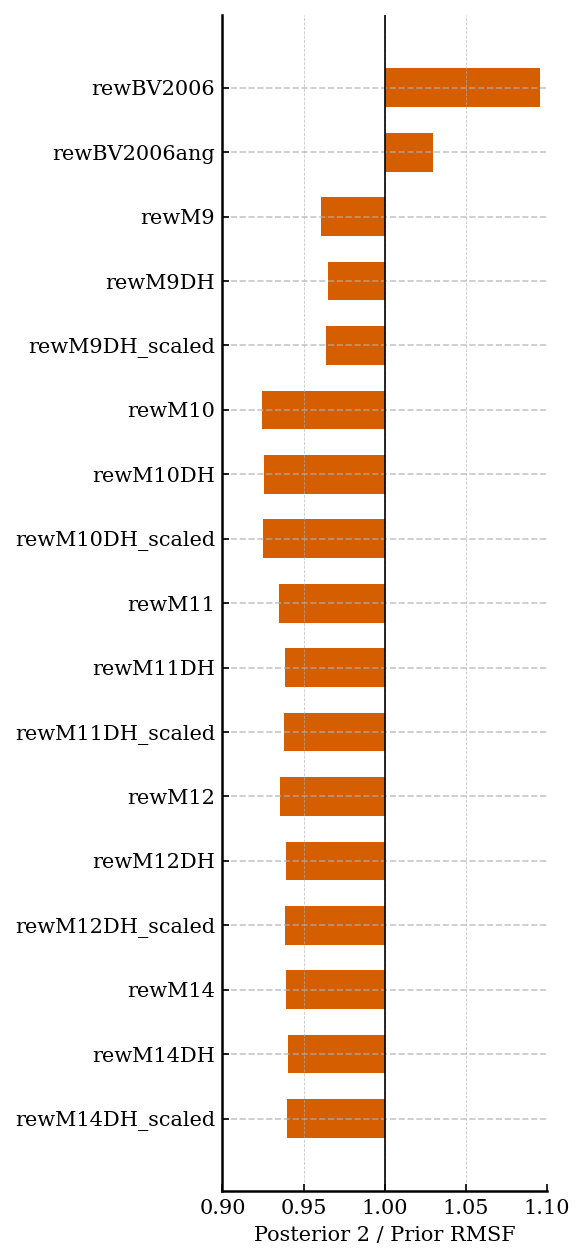

In [5]:
# ---------------------------------------------------------
# Lists
# ---------------------------------------------------------
models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled', 'rewM14', 'rewM14DH', 'rewM14DH_scaled']

proteins = ['ACBP','ACP','alpha3D','At2g44940','Barnase','BarstarK60','betalactamasePSE4','BPTI','Calbindin','CalcineurinB','CI2','ci2_I29A_I37H','DAXX','FKBP12',
            'Galectin1','GB3','H14','hFGF1','Hisactophilin1','HIVintegrase','HP36','Im7','Jarastatin','Lactalbumin','lDHFR','Lysozyme','NHP2L1','PeroxiredoxinQ','RNaseA',
            'RNaseH','RNaseT1','SAMP1','Staph_nuclease_P117G_H124L','T4_lysozyme','Ubiquitin']

# ---------------------------------------------------------
# Calculate mean posterior / prior RMSF ratio for each model
# ---------------------------------------------------------
mean_ratios = []

for model in models:
    prior = np.array([])
    posterior = np.array([])

    for protein in proteins:
        file = outpath + f"{protein}_{model}_RMSF.csv"
        if not os.path.exists(file):
            print(f'No data for {protein}/{model}, skipping ...')
            continue
        dat = pd.read_csv(file)
        prior = np.concatenate((prior, dat['Prior'].to_numpy()))
        posterior = np.concatenate((posterior, dat['Posterior'].to_numpy()))

    ratio = posterior / prior
    mean_ratio = np.nanmean(ratio)
    mean_ratios.append(mean_ratio)
    print(f'{model}: mean posterior/prior RMSF = {mean_ratio:.3f}')

mean_ratios = np.array(mean_ratios)
delta_ratios = mean_ratios - 1.0

# ---------------------------------------------------------
# Horizontal bar plot centred on 1.0
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(4, max(4, 0.5 * len(models))))

y = np.arange(len(models))

ax.barh(y, delta_ratios, left=1.0, height=0.6, color="#D55E00")

ax.axvline(1.0, color="black", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(models)
ax.set_xlim(0.9, 1.1)
ax.set_xticks([0.9, 0.95, 1.0, 1.05, 1.1])
ax.set_xlabel("Posterior 2 / Prior RMSF")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", linewidth=0.4)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="both", top=False, right=False)

plt.tight_layout()
plt.savefig(outpath + "FoldedProteins_RMSF_PosteriorPrior_Ratio_centered.pdf", dpi=300, bbox_inches="tight")
plt.show()